# Transient 1D Heat equation
## Models the diffusion of heat in a one-dimensional medium with respect to time.
## Solution obtained using DeepXDE.

## The transient 1D  heat equation can be written as:

$$
\begin{equation}
\frac{\partial U}{\partial t} = k * \frac{\partial^2 U}{\partial x^2}
\end{equation}
$$

### where U(x, t) is the temperature dependent upon x (spatial variable) and t (temporal variable).

## We will obtain the solution for the Dirichlet Boundary Condition:

#### $U(0, t) = U(1, t) = 0$

## Initial Condition (t=0):

#### $U(x, 0) = sin(\pi * x)$

In [21]:
# This is a generalized version of a solution methodology using DeepXDE for 1d PDE
# Modified by: Parag Adhangale, PhD
#======================================================================
# Set the backend to PyTorch (can also be 'tensorflow' or 'jax')
#
import os
os.environ["DDE_BACKEND"] = "pytorch"
#
import numpy as np
import deepxde as dde

In [22]:
#
# 1. Define the computational domain (1D Space + 1D Time)
#
spatial_domain = dde.geometry.Interval(0, 1)
temporal_domain = dde.geometry.TimeDomain(0, 1)
geomtime = dde.geometry.timedomain.GeometryXTime(spatial_domain, temporal_domain)

In [23]:
#
# 2. Define the governing PDE system
#
def heat_equation(x, u):

#   x[:, 0]: spatial coordinate (x)
#   x[:, 1]: temporal coordinate (t)
#   u: network prediction for temperature

#  First derivative with respect to time (t is index 1)
   du_dt = dde.grad.jacobian(u, x, i=0, j=1)   

#  Second derivative with respect to space (x is index 0)
   d2u_dx2 = dde.grad.hessian(u, x, i=0, j=0)

#  Thermal diffusivity constant
   k = 0.4

   return du_dt - k * d2u_dx2

In [24]:
#
# 3. Define the Boundary and Initial Conditions
#
#    Neumann boundary conditions: 
#      dde.icbc.NeumannBC(geom, val_func, boundary_func) -- Sets normal
#          derivative du_dx = f(x)
#
#    Robin boundary conditions: 
#      dde.icbc.RobinBC(geom, val_func, boundary_func) -- Sets linear
#          combination a * u + b * du_dx = c
#
#    Periodic boundary conditions:
#      dde.icbc.PeriodicBC(geom, ic_func, boundary_func) 
#
#    Initial condition:
#      dde.icbc.IC(geom, ic_func, boundary_func) -- Sets condition
#          at t = 0
#
#    Dirichlet boundary conditions: 
#      dde.icbc.DirichletBC(geom, val_func, boundary_func) = Sets
#          value u = f(x)
#
#     u(0, t) = 0 & u(1, t) = 0
#
bc = dde.icbc.DirichletBC(
      geomtime,
      lambda x: 0,
      lambda x, on_boundary: on_boundary,
      component = 0
)
#
#     Initial condition: u(x, 0) = sin(pi * x)
#
def initial_condition(x):
   return np.sin(np.pi * x[:, 0:1])
#
ic = dde.icbc.IC(
   geomtime, 
   initial_condition,
   lambda x, on_initial: on_initial
)

In [25]:
#
# 4. Combine into a PINN data object
#
data = dde.data.TimePDE(
   geomtime,
   heat_equation,
   [bc, ic],
   num_domain=2000,   # Residual collocation points inside the domain
   num_boundary=100,  # Training points along spatial coordinates
   num_initial=100,   # Training points along the t=0 initial slice
   num_test=10000     # Testing points for evaluation
)

In [26]:
#
# 5. Define the Neural Network Architecture
#
#    2 inputs (x, t) -> 3 hidden layers -> 1 output (u)
layer_size = [2, 32, 32, 32, 1]
#    Smooth activation function required for second derivatives
activation = "tanh"
#    Standard weight initialization
initializer = "Glorot normal"
#
net = dde.nn.FNN(layer_size, activation, initializer)

In [27]:
#
# 6. Compile, Train, and Optimize the Model
#
#    Compile the model:
model = dde.Model(data, net)
model.compile("adam", lr=1e-3)
#
#    Train the model:
losshistory, train_state = model.train(iterations=20000)
#
#    Optimize the model
#    Additional training with L-BFGS (optional)
#    to lower the loss:
#         model compile("L-BFGS-B")
#         losshistory, train_state = model.train()
#

Compiling model...
'compile' took 0.000433 s

Training model...

Step      Train loss                        Test loss                         Test metric
0         [9.88e-02, 5.07e-02, 4.36e-01]    [9.68e-02, 5.07e-02, 4.36e-01]    []  
1000      [6.43e-04, 2.30e-04, 4.54e-05]    [3.91e-04, 2.30e-04, 4.54e-05]    []  
2000      [1.27e-04, 4.95e-05, 5.91e-06]    [8.70e-05, 4.95e-05, 5.91e-06]    []  
3000      [5.59e-05, 2.81e-05, 4.23e-06]    [3.71e-05, 2.81e-05, 4.23e-06]    []  
4000      [3.45e-05, 1.91e-05, 2.15e-06]    [2.35e-05, 1.91e-05, 2.15e-06]    []  
5000      [2.54e-05, 1.31e-05, 1.48e-06]    [1.78e-05, 1.31e-05, 1.48e-06]    []  
6000      [3.23e-05, 1.67e-05, 3.21e-06]    [2.25e-05, 1.67e-05, 3.21e-06]    []  
7000      [1.58e-05, 6.62e-06, 6.00e-07]    [1.12e-05, 6.62e-06, 6.00e-07]    []  
8000      [1.32e-05, 4.61e-06, 4.28e-07]    [9.37e-06, 4.61e-06, 4.28e-07]    []  
9000      [1.17e-05, 6.73e-06, 3.12e-06]    [8.08e-06, 6.73e-06, 3.12e-06]    []  
10000     [1.04

In [34]:
#
# 7. Save data for later plotting
#
#
#XX    Save raw scattered columns: x, t, u_pred
#XX
#XX      u_pred = model.predict(geomtime)
#XX      test_data = np.hstack((geomtime, u_pred))
#XX      np.savetext("Raw_soln.dat", test_data, headers="x t u")
#XX    To plot this raw data, you will have to interpolate it onto
#XX    a grid using scipy.interpolate.griddata
#XX       
#XX                    OR
#      
#    Create uniform grids for plotting
#
n_x = 100
n_t = 10
x_plot = np.linspace(0, 1, n_x)
t_plot = np.linspace(0, 1, n_t)
#
X, T = np.meshgrid(x_plot, t_plot)
#
#    Reshape into the (N, 2) input format DeepXDE expects [x, t]
#
X_grid = np.vstack((X.flatten(), T.flatten())).T
#
#    Get model predictions for this grid
#
u_pred = model.predict(X_grid)
#
#    Reshape the solution back to match the 2D grid shape (time, space)
#
u_grid = u_pred.reshape(X.shape)
#
#    Save arrays into a single compressed file
#
np.savez("Heateqn_soln.npz", x=x_plot, t=t_plot,u=u_grid)
#
#    To load this data back:
#
# datan = np.load("Heateqn_soln.npz")
# x = datan["x"]
# t = datan["t"]
# u = datan["u"]

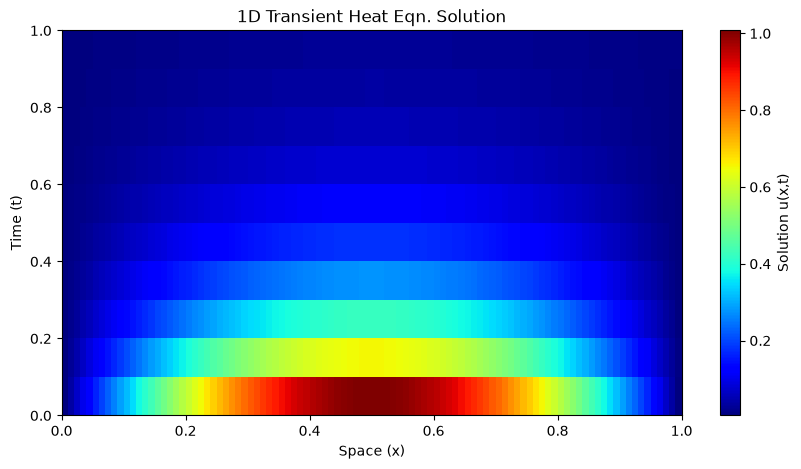

In [35]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.imshow(
   u_grid,
   extent=[0, 1, 0, 1],   
   origin="lower",
   aspect="auto",
   cmap="jet"
)
plt.colorbar(label="Solution u(x,t)")
plt.xlabel("Space (x)")
plt.ylabel("Time (t)")
plt.title("1D Transient Heat Eqn. Solution")
plt.show()

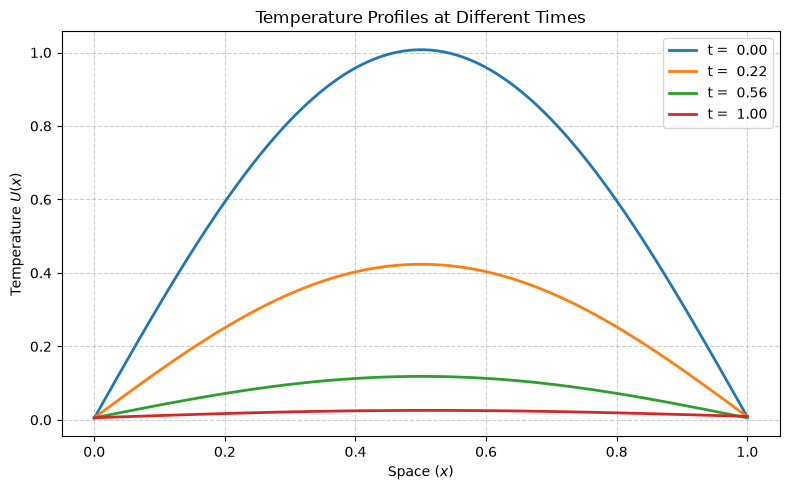

In [36]:
#
# Plot 1D snapshots in time
# Select time indices you want to look at:
#
time_snaps = [0, int(n_t * 0.2), int(n_t * 0.5), n_t -1]
plt.figure(figsize=(8, 5))
for idt in time_snaps:
    curr_time = t_plot[idt]
    plt.plot(x_plot, u_grid[idt, :], label=f't = {curr_time: 0.2f}', lw=2)

plt.xlabel('Space ($x$)')
plt.ylabel('Temperature $U(x)$')
plt.title('Temperature Profiles at Different Times')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()